# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Климчук Юрій Олегович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 9      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 9, файл lr6_варіант_09.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: треба передбачити один з двох класів (піде клієнт чи ні), а не число

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# AUC не залежить від порогу і від частки відтоку (26 %); точність «ніхто не піде» дала б 73,6 %, хоч така модель нічого не вміє

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# відтоку лише 26 %, тому стратифікація зберігає його частку в кожній згортці, а 4 повтори дають 20 оцінок і видно розкид

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.264

типи стовпців: {'str': 13, 'float64': 7, 'int64': 6}


In [6]:
profile = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'унікальних': raw.nunique(),
    '% пропусків': (raw.isna().mean() * 100).round(1),
    'приклад': [raw[c].dropna().iloc[0] for c in raw.columns],
}).rename_axis('стовпець').sort_values('% пропусків', ascending=False)
display(profile)

,тип,унікальних,% пропусків,приклад
стовпець,,,,
сума_повернення_депозиту,float64,316,73.6,406.22
дата_розірвання,str,262,73.6,2023-12-10
середній_час_відповіді_хв,float64,265,33.6,1.7
трафік_ГБ,str,965,5.0,98.4
щомісячний_платіж,str,1123,4.0,216.89
аварій_на_ділянці_за_квартал,float64,6,3.0,0.0
стать,str,6,0.0,Ч
місто,str,6,0.0,Дрогобич
id_клієнта,str,1200,0.0,K90000


У таблиці 1200 рядків і 26 стовпців, разом із цільовим. Частка відтоку 26,4 %. Текстовий тип мають 13 стовпців, але справжніх категорій серед них лише 8, решта це id, дві дати та два числові стовпці, які прочитались як текст. Найбільше пропусків у сума_повернення_депозиту та дата_розірвання (по 73,6 %), далі середній_час_відповіді_хв (33,6 %).

### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
txt = raw['щомісячний_платіж'].str.contains('грн', na=False)
print(txt.sum(), raw.loc[txt, 'щомісячний_платіж'].head(5).tolist())

dt = raw['трафік_ГБ'].str.startswith('1900', na=False)
print(dt.sum(), raw.loc[dt, 'трафік_ГБ'].head(5).tolist())

no_resp = raw['середній_час_відповіді_хв'].isna()
print(raw.groupby(no_resp)['кількість_звернень_у_підтримку'].agg(['mean', 'max', 'size']))
print(raw.groupby(no_resp)[TARGET].mean())

26 ['333.56 грн', '329.35 грн', '325.24 грн', '328.96 грн', '204.79 грн']
3 ['1900-01-05 00:00:00', '1900-01-02 00:00:00', '1900-01-05 00:00:00']
                              mean  max  size
середній_час_відповіді_хв                    
False                      1.65872    6   797
True                       0.00000    0   403
середній_час_відповіді_хв
False    0.29862
True     0.19603
Name: відтік, dtype: float64


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = 'пропуск означає, що клієнт жодного разу не звертався у підтримку (звернень 0), тож часу відповіді просто немає'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        if pd.isna(v):
            return np.nan
        if isinstance(v, (datetime.datetime, pd.Timestamp)):
            return np.nan
        if isinstance(v, (int, float)):
            return float(v)
        if re.match(r'\d{4}-\d{2}-\d{2}', str(v)):
            return np.nan
        m = re.search(r'\d+(?:[.,]\d+)?', str(v))
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        if c.startswith('дата_'):
            X[c] = (pd.to_datetime(d[c]) - pd.Timestamp('2023-01-01')).dt.days.astype(float)
            log.append({'стовпець': c, 'рішення': 'дата -> номер дня'})
        elif pd.api.types.is_numeric_dtype(d[c]):
            X[c] = d[c].astype(float)
            log.append({'стовпець': c, 'рішення': 'число'})
        else:
            n = to_number(d[c])
            if n.notna().sum() > 0.8 * d[c].notna().sum() and not d[c].str.match(r'\D+\d').any():
                X[c] = n
                log.append({'стовпець': c, 'рішення': 'текст -> число'})
            else:
                X[c] = d[c].str.strip().str.lower().astype('category')
                log.append({'стовпець': c, 'рішення': 'категорія'})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,рішення
0,вік,число
1,стать,категорія
2,місто,категорія
3,філія,категорія
4,тариф,категорія
5,тип_підключення,категорія
6,спосіб_оплати,категорія
7,автоплатіж,категорія
8,кількість_послуг,число
9,місяців_обслуговування,число


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    num = [c for c in X.columns if c not in cat]
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
    ])
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.953


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.954 ± 0.013
час      : 0.8 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = 'AUC 0,954 означає, що майже завжди модель ставить вищий ризик тому, хто пішов, а не тому, хто лишився. Для відтоку так добре не буває, тому з двох причин (задача справді легка або у даних є витік) найімовірніше спрацювала друга: у вивантаженні є колонки, які з’являються вже після розриву договору.'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0,954 означає, що майже завжди модель ставить вищий ризик тому, хто пішов, а не тому, хто лишився. Для відтоку так добре не буває, тому з двох причин (задача справді легка або у даних є витік) найімовірніше спрацювала друга: у вивантаженні є колонки, які з’являються вже після розриву договору.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        score = 0.5
        if filled.sum() >= min_group and (~filled).sum() >= min_group:
            score = roc_auc_score(y, filled.astype(int))
            score = max(score, 1 - score)
        rows.append({'ознака': c, 'заповнено': int(filled.sum()),
                     'частка_відтоку_де_заповнено': y[filled].mean(),
                     'частка_відтоку_де_пропуск': y[~filled].mean(),
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,дата_розірвання,317,1.000000,0.000000,1.000000
23,сума_повернення_депозиту,317,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,797,0.298620,0.196030,0.558860
12,щомісячний_платіж,1152,0.258681,0.395833,0.513547
14,трафік_ГБ,1140,0.261404,0.316667,0.506752
16,аварій_на_ділянці_за_квартал,1164,0.266323,0.194444,0.505380
2,стать,1200,0.264167,NaN,0.500000
1,вік,1200,0.264167,NaN,0.500000
0,id_клієнта,1200,0.264167,NaN,0.500000
8,автоплатіж,1200,0.264167,NaN,0.500000


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'дата_розірвання',            # є лише в тих, хто вже пішов, бо записується в момент розірвання договору
    'сума_повернення_депозиту',   # депозит повертають при розірванні, у чинного клієнта такої суми немає
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['дата_розірвання', 'сума_повернення_депозиту']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.943 ± 0.015


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
print(list(X2.columns))
display(raw.groupby('кількість_дзвінків_утримання')[TARGET].agg(['mean', 'size']).round(3))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'номер_договору_серія', 'індекс_лояльності_CRM', 'дата_підключення', 'кількість_дзвінків_утримання']


,mean,size
кількість_дзвінків_утримання,,
0,0.049,819
1,0.662,68
2,0.815,81
3,0.705,88
4,0.735,68
5,0.711,76


In [18]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання',   # відділ утримання дзвонить клієнту, коли той уже сказав, що збирається піти
]
HUMAN_LEAK_WHY = 'Колонка заповнена в усіх клієнтів (де дзвінків не було, стоїть 0, а не пропуск), тому заповненість нічого не каже про клас. Дзвінки утримання роблять уже після того, як клієнт заявив про намір піти: серед тих, кому дзвонили, пішло 66–82 %, а серед тих, кому ні, лише 4,9 %.'      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.858 ± 0.022


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,mean,size
філія,,
Ф-01 Центр,0.306,206
Ф-02 Захід,0.260,177
Ф-03 Схід,0.288,208
Ф-04 Південь,0.247,190
Ф-05 Північ,0.256,207
Ф-06 Приміська,0.226,212


,mean,size
дата_підключення,,
2023Q1,0.178,152
2023Q2,0.165,127
2023Q3,0.180,150
2023Q4,0.150,160
2024Q1,0.224,156
2024Q2,0.335,155
2024Q3,0.416,154
2024Q4,0.459,146


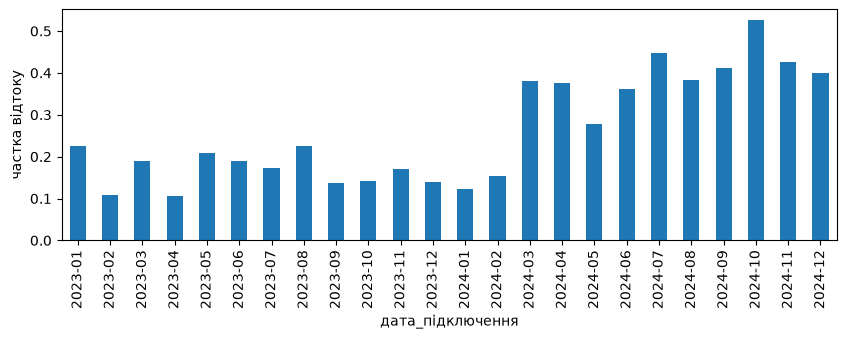

In [19]:
display(raw.groupby('філія')[TARGET].agg(['mean', 'size']).round(3))

q = pd.to_datetime(raw['дата_підключення'])
display(raw.groupby(q.dt.to_period('Q'))[TARGET].agg(['mean', 'size']).round(3))

monthly = raw.groupby(q.dt.to_period('M'))[TARGET].mean()
monthly.index = monthly.index.astype(str)
monthly.plot(kind='bar', figsize=(10, 3), ylabel='частка відтоку')
plt.show()

По філіях відтік відрізняється мало, від 22,6 % у Ф-06 до 30,6 % у Ф-01, сходинки немає. По кварталах підключення вона є: у 2023 році відтік 15–18 %, у 2024Q1 22 %, далі 34 %, 42 % і 46 %. На помісячному графіку злам припадає на березень 2024: у січні та лютому було 12 і 15 %, а з березня 38 % і вище, і назад не повертається. Підозрюю дату підключення.

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'дата_підключення'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

source = (pd.to_datetime(raw['дата_підключення']) >= '2024-03-01').astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.806
ті самі ознаки передбачають ВІДТІК  : AUC 0.828 ± 0.020


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.954
2. мінус цільовий витік,22,0.943
3. мінус оцінки людини,21,0.858
4. мінус артефакт збору,20,0.828


чесне число: 0.828 ± 0.020


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = 'У клієнтів, підключених з березня 2024, відтік 40 % проти 16 % раніше, причому різко, в один місяць і в усіх філіях. Це більше схоже на зміну способу збору даних, ніж на реальну зміну поведінки, яка була б поступовою. Решта ознак і без дати вгадує період з AUC 0,806, тож артефакт цим повністю не прибрати, але саму дату підключення використовувати для прогнозу немає сенсу.'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — У клієнтів, підключених з березня 2024, відтік 40 % проти 16 % раніше, причому різко, в один місяць і в усіх філіях. Це більше схоже на зміну способу збору даних, ніж на реальну зміну поведінки, яка була б поступовою. Решта ознак і без дати вгадує період з AUC 0,806, тож артефакт цим повністю не прибрати, але саму дату підключення використовувати для прогнозу немає сенсу.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.828,0.020,0.8
одне дерево,0.746,0.032,0.6
випадковий ліс,0.816,0.029,11.0
гістограмний бустинг,0.813,0.022,5.9


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    diff = np.asarray(b) - np.asarray(a)
    return diff.mean(), 1.96 * diff.std(ddof=1) / np.sqrt(len(diff))


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: -0.0119 ± 0.0093   значуще


гістограмний бустинг   проти логістичної: -0.0145 ± 0.0091   значуще


In [25]:
CHOSEN_MODEL = 'логістична регресія'     # назва з MODELS
CHOSEN_WHY = 'Вона дала найвищий AUC (0,828 проти 0,816 у лісу і 0,813 у бустингу) і найменший розкид (0,020), а парне порівняння показало, що ліс і бустинг гірші значуще (різниця -0,012 і -0,015 при півширині 0,009). До того ж вона найшвидша (0,8 с проти 10,4 с у лісу) і найпростіша для пояснення.'       # за якими з чотирьох критеріїв і чому саме так
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — Вона дала найвищий AUC (0,828 проти 0,816 у лісу і 0,813 у бустингу) і найменший розкид (0,020), а парне порівняння показало, що ліс і бустинг гірші значуще (різниця -0,012 і -0,015 при півширині 0,009). До того ж вона найшвидша (0,8 с проти 10,4 с у лісу) і найпростіша для пояснення.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # гіпотеза: клієнт, який платить багато за малу швидкість, відчуває переплату і йде
    F['платіж_на_мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    # гіпотеза: тим, хто платить за гігабайти мало, тариф невигідний
    F['трафік_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж']
    # гіпотеза: частота звернень важливіша за їхню абсолютну кількість, бо в старого клієнта вони накопичуються роками
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / F['місяців_обслуговування']
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 23


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.829 ± 0.021
приріст проти базового набору: +0.0009 ± 0.0024   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = 'Нові ознаки дали +0,0009 ± 0,0024 AUC, тобто нічого, але майже безкоштовно (близько секунди на 20 навчань логістичної регресії). Складніші моделі дали навіть менше: ліс -0,012 за 10,4 с, бустинг -0,015 за 5,8 с. Отже ні той, ні інший шлях тут не допоміг, просто ознаки нічого не коштували.'
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Нові ознаки дали +0,0009 ± 0,0024 AUC, тобто нічого, але майже безкоштовно (близько секунди на 20 навчань логістичної регресії). Складніші моделі дали навіть менше: ліс -0,012 за 10,4 с, бустинг -0,015 за 5,8 с. Отже ні той, ні інший шлях тут не допоміг, просто ознаки нічого не коштували.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.818
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

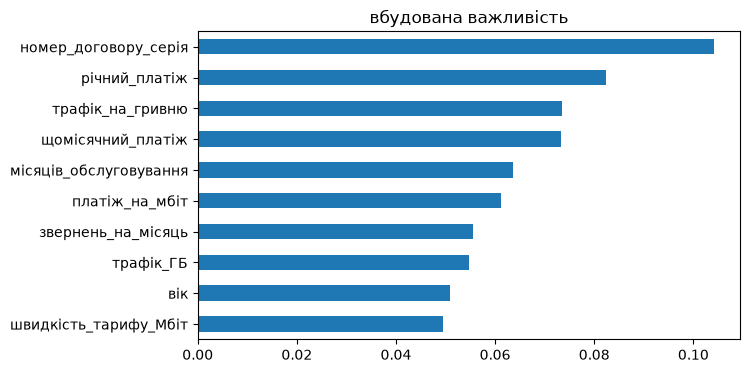

In [30]:
names = model.named_steps['prep'].get_feature_names_out()
orig = [max((c for c in FINAL_X.columns
             if n.split('__', 1)[1] == c or n.split('__', 1)[1].startswith(c + '_')), key=len)
        for n in names]
gini_imp = pd.Series(model.named_steps['clf'].feature_importances_, index=orig)
gini_imp = gini_imp.groupby(level=0).sum().sort_values(ascending=False)
gini_imp.head(10)[::-1].plot(kind='barh', figsize=(7, 4), title='вбудована важливість')
plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
трафік_на_гривню,0.040238
місяців_обслуговування,0.034528
трафік_ГБ,0.018457
кількість_послуг,0.013027
річний_платіж,0.011221
щомісячний_платіж,0.005845
вік,0.005738
автоплатіж,0.004836
аварій_на_ділянці_за_квартал,0.003289
швидкість_тарифу_Мбіт,0.002556


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
cmp_imp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp})
display(cmp_imp.sort_values('вбудована', ascending=False).head(10).round(4))

,вбудована,перестановочна
номер_договору_серія,0.1042,0.0011
річний_платіж,0.0824,0.0112
трафік_на_гривню,0.0736,0.0402
щомісячний_платіж,0.0733,0.0058
місяців_обслуговування,0.0635,0.0345
платіж_на_мбіт,0.0611,0.0006
звернень_на_місяць,0.0556,0.0014
трафік_ГБ,0.0547,0.0185
вік,0.0510,0.0057
швидкість_тарифу_Мбіт,0.0494,0.0026


In [33]:
FAKE_IMPORTANT = 'індекс_лояльності_CRM'        # назва ознаки
FAKE_IMPORTANT_WHY = 'номер_договору_серія має 55 різних значень, після одиничного кодування це 55 стовпців, і в кожного дерево знаходить якийсь поріг, що трохи зменшує неоднорідність. Сума по 55 стовпцях вийшла найбільшою (0,104, перше місце), а перестановка на перевірковій частині дає лише 0,0011.'    # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: індекс_лояльності_CRM


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
corr = FINAL_X.select_dtypes('number').corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
display(pairs[pairs.abs() > 0.97])

щомісячний_платіж  річний_платіж    0.999054
dtype: float64

In [35]:
DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

Xtr_d = Xtr.drop(columns=DUP_PAIR[1])
Xte_d = Xte.drop(columns=DUP_PAIR[1])
model_d = make_pipe(Xtr_d, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr_d, ytr)
perm_d = permutation_importance(model_d, Xte_d, yte, n_repeats=10, random_state=SEED, scoring='roc_auc')
perm_d = pd.Series(perm_d.importances_mean, index=Xte_d.columns)
print('без %s:' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_d[DUP_PAIR[0]]))

у повній моделі:
   щомісячний_платіж            +0.0058
   річний_платіж                +0.0112


без річний_платіж:
   щомісячний_платіж            +0.0160


In [36]:
DUP_EXPLANATION = 'Це одна й та сама ознака: річний платіж приблизно дорівнює 12 щомісячним, кореляція 0,999. У повній моделі перемішування однієї колонки її не ламає, бо інформація є в другій, тому важливість лише 0,0058 і 0,0112. Коли я прибрав річний_платіж, важливість щомісячного зросла до 0,0160, тобто приблизно до суми двох. Висновок «важливість майже нуль, отже колонку можна викинути» був би хибним.'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

Це одна й та сама ознака: річний платіж приблизно дорівнює 12 щомісячним, кореляція 0,999. У повній моделі перемішування однієї колонки її не ламає, бо інформація є в другій, тому важливість лише 0,0058 і 0,0112. Коли я прибрав річний_платіж, важливість щомісячного зросла до 0,0160, тобто приблизно до суми двох. Висновок «важливість майже нуль, отже колонку можна викинути» був би хибним.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

['місяців_обслуговування', 'кількість_послуг', 'річний_платіж']


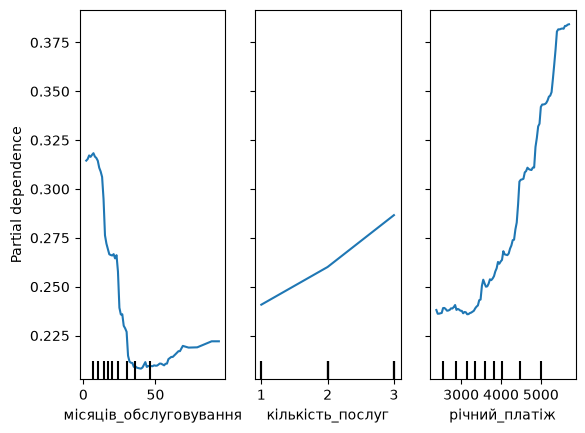

In [37]:
from sklearn.inspection import PartialDependenceDisplay

num_ok = [c for c in perm_imp.index
          if str(FINAL_X[c].dtype) != 'category' and FINAL_X[c].notna().all()]
top3 = num_ok[:3]
print(top3)
PartialDependenceDisplay.from_estimator(model, Xte, features=top3, kind='average')
plt.show()

місяців_обслуговування: у перші півтора року ризик високий (близько 0,31), потім різко падає до 0,21 на 30–35 місяцях і далі майже не змінюється. Тобто найбільше йдуть нові клієнти. кількість_послуг: майже пряма лінія вгору від 0,24 при одній послузі до 0,29 при трьох, чим більше послуг, тим вищий ризик. річний_платіж: до 3500 грн крива пласка (близько 0,24), потім зростає до 0,38 при 5500 грн, тобто дорогі тарифи йдуть охочіше.

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

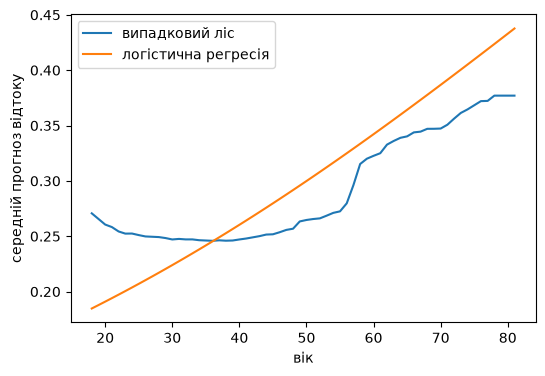

In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

lr_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(6, 4))
for name, m in [('випадковий ліс', model), ('логістична регресія', lr_model)]:
    r = partial_dependence(m, FINAL_X, [NONLINEAR_FEATURE], kind='average')
    ax.plot(r['grid_values'][0], r['average'][0], label=name)
ax.set_xlabel(NONLINEAR_FEATURE)
ax.set_ylabel('середній прогноз відтоку')
ax.legend()
plt.show()

In [39]:
NONLINEAR_MEANING = 'найрідше йдуть клієнти приблизно 36 років, а молоді (до 25) і літні (60+) йдуть частіше: у сирих даних відтік 30 % до 25 років, 20 % у 30–40 і 44 % після 60. Крива логістичної регресії на графіку лише зростає, тому цієї форми вона не бачить'     # що означає ця форма змістовно, мовою предметної області
NONLINEAR_FIX = 'вік_квадрат = (вік − 36)², тобто квадрат відхилення від віку з мінімальним ризиком'         # яку ознаку треба сконструювати, щоб лінійна модель це побачила
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

найрідше йдуть клієнти приблизно 36 років, а молоді (до 25) і літні (60+) йдуть частіше: у сирих даних відтік 30 % до 25 років, 20 % у 30–40 і 44 % після 60. Крива логістичної регресії на графіку лише зростає, тому цієї форми вона не бачить
вік_квадрат = (вік − 36)², тобто квадрат відхилення від віку з мінімальним ризиком


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
r = partial_dependence(model, FINAL_X, ['вік'], kind='average')
AGE_MIN = float(r['grid_values'][0][np.argmin(r['average'][0])])
print('мінімум ризику при віці', AGE_MIN)

Xq = FINAL_X.copy()
Xq['вік_квадрат'] = (Xq['вік'] - AGE_MIN) ** 2

auc_lin = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
auc_quad = cross_val_score(make_pipe(Xq, logreg()), Xq, y, cv=cv, scoring='roc_auc')
QUAD_GAIN, half = paired(auc_lin, auc_quad)
print('AUC без: %.3f, з: %.3f, приріст %+.4f ± %.4f' % (auc_lin.mean(), auc_quad.mean(), QUAD_GAIN, half))

мінімум ризику при віці 36.0


AUC без: 0.829, з: 0.840, приріст +0.0114 ± 0.0024


In [41]:
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0114


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

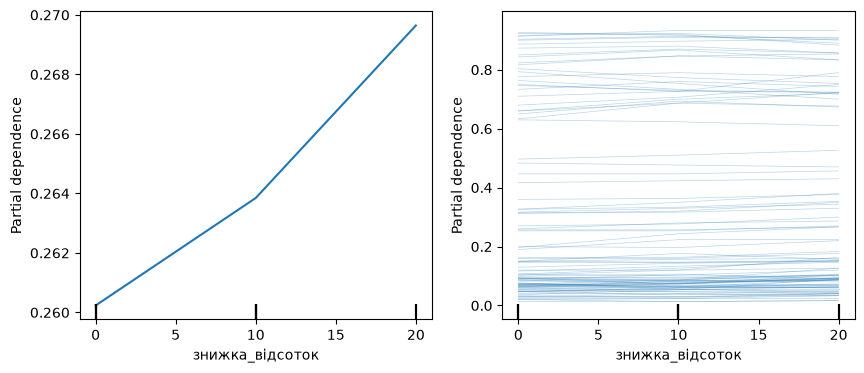

In [42]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=axs[0])
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='individual',
                                        subsample=100, random_state=SEED, ax=axs[1])
plt.show()

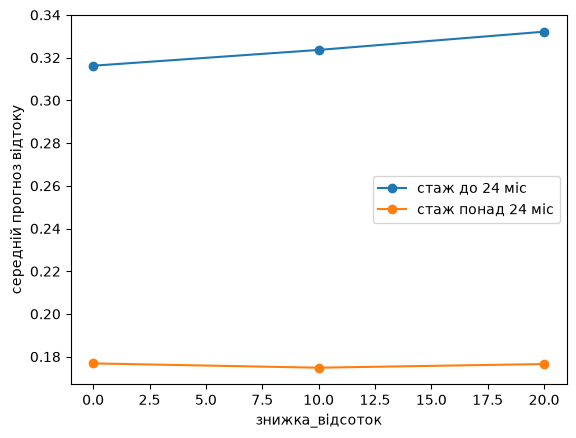

In [43]:
short = FINAL_X['місяців_обслуговування'] <= 24
for mask, label in [(short, 'стаж до 24 міс'), (~short, 'стаж понад 24 міс')]:
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    plt.plot(r['grid_values'][0], r['average'][0], marker='o', label=label)
plt.xlabel('знижка_відсоток')
plt.ylabel('середній прогноз відтоку')
plt.legend()
plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
grp = np.where(raw['місяців_обслуговування'] <= 24, 'до 24 міс', 'понад 24 міс')
tab = raw.groupby([grp, 'знижка_відсоток'])[TARGET].agg(['mean', 'size']).round(3)
display(tab)

mean  size
             знижка_відсоток             
до 24 міс    0                0.278   291
             10               0.347   245
             20               0.445   182
понад 24 міс 0                0.207   184
             10               0.133   165
             20               0.075   133

In [45]:
two = FINAL_X[['знижка_відсоток', 'місяців_обслуговування']]
m2 = make_pipe(two, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(two, y)
for mask, label in [(short, 'до 24 міс'), (~short, 'понад 24 міс')]:
    r = partial_dependence(m2, two[mask], ['знижка_відсоток'], kind='average')
    print(label, r['average'][0].round(3))

до 24 міс [0.285 0.364 0.46 ]
понад 24 міс [0.212 0.125 0.074]


In [46]:
INTERACTION_FOUND = 'У клієнтів зі стажем до 24 місяців знижка збільшує відтік: 27,8 % без знижки, 34,7 % при 10 % і 44,5 % при 20 %. У клієнтів зі стажем понад 24 місяці навпаки: 20,7 %, 13,3 % і 7,5 %. Повна модель (ліс) цю картину відтворює слабко: у нових клієнтів її середній прогноз росте лише з 0,316 до 0,332, у давніх майже пласка (близько 0,18), тому ICE на всій вибірці майже пласкі, а PDP по всій вибірці росте лише з 0,260 до 0,270. Ліс лише на двох ознаках (знижка і стаж) відтворює її добре (0,285 → 0,460 і 0,212 → 0,074), отже в повній моделі ефект розмився серед інших ознак, і питання тут до моделі, а не до PDP.'     # опишіть, що робить знижка в кожній із двох груп
BUSINESS_ACTION = 'Не давати знижки всім підряд. Пропонувати її клієнтам зі стажем понад 24 місяці, де в даних відтік падає з 21 % до 8 %, а для нових клієнтів шукати інший спосіб утримання, бо знижка їм, судячи з даних, не допомагає. Це зв’язок у даних, а не експеримент, тому спершу варто перевірити на невеликій групі.'       # що з цього випливає для відділу утримання
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

У клієнтів зі стажем до 24 місяців знижка збільшує відтік: 27,8 % без знижки, 34,7 % при 10 % і 44,5 % при 20 %. У клієнтів зі стажем понад 24 місяці навпаки: 20,7 %, 13,3 % і 7,5 %. Повна модель (ліс) цю картину відтворює слабко: у нових клієнтів її середній прогноз росте лише з 0,316 до 0,332, у давніх майже пласка (близько 0,18), тому ICE на всій вибірці майже пласкі, а PDP по всій вибірці росте лише з 0,260 до 0,270. Ліс лише на двох ознаках (знижка і стаж) відтворює її добре (0,285 → 0,460 і 0,212 → 0,074), отже в повній моделі ефект розмився серед інших ознак, і питання тут до моделі, а не до PDP.
Не давати знижки всім підряд. Пропонувати її клієнтам зі стажем понад 24 місяці, де в даних відтік падає з 21 % до 8 %, а для нових клієнтів шукати інший спосіб утримання, бо знижка їм, судячи з даних, не допомагає. Це зв’язок у даних, а не експеримент, тому спершу варто перевірити на невеликій групі.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [47]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 98)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

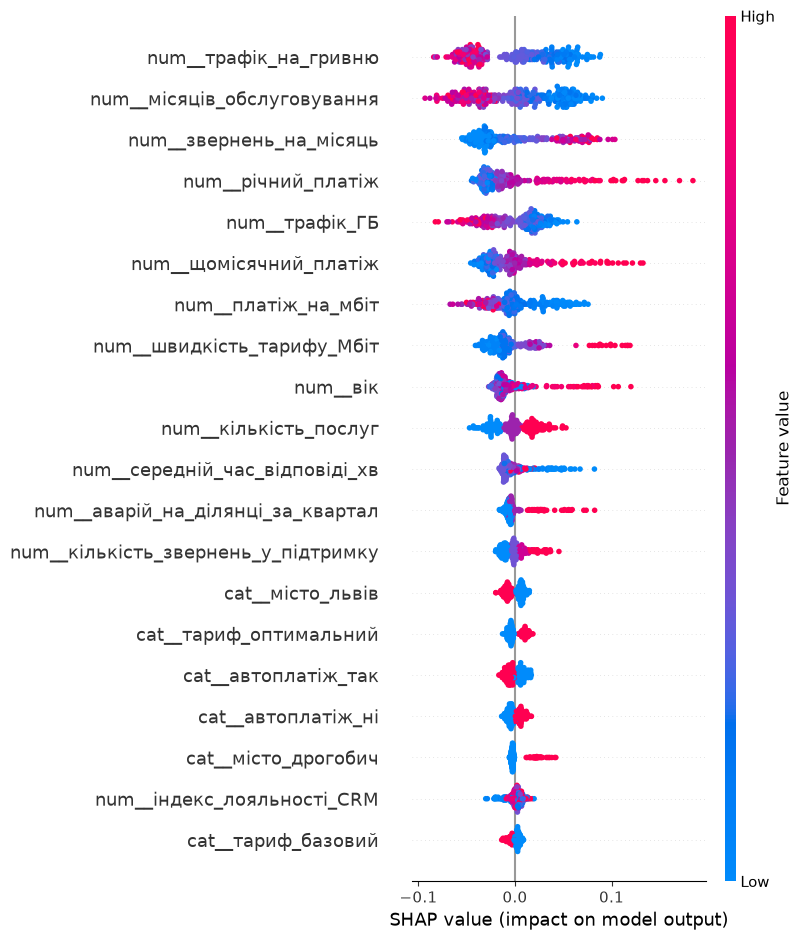

In [48]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names)

Найбільші внески дають трафік_на_гривню, місяців_обслуговування і звернень_на_місяць. Чим більші річний_платіж, щомісячний_платіж, швидкість тарифу і вік, тим правіше точки, тобто ризик вищий, а чим більше місяців обслуговування і трафіку на гривню, тим лівіше. Для більшості ознак напрям однаковий у всіх клієнтів, різниться лише розкид: наприклад, швидкість сильно штовхає ризик угору лише у невеликої групи клієнтів з дуже швидкими тарифами. індекс_лояльності_CRM майже внизу списку.

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [49]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

contrib = sv1[idx]
for i in np.argsort(-np.abs(contrib))[:3]:
    print('%-45s внесок %+.3f' % (feat_names[i], contrib[i]))
display(Xte.iloc[[idx]].T)

ризик клієнта: 0.883
num__річний_платіж                            внесок +0.099
num__швидкість_тарифу_Мбіт                    внесок +0.090
num__щомісячний_платіж                        внесок +0.078


,27
вік,59.0
стать,ч
місто,дрогобич
філія,ф-03 схід
тариф,базовий
тип_підключення,оптика
спосіб_оплати,каса
автоплатіж,так
кількість_послуг,3.0
місяців_обслуговування,8.0


In [50]:
EXPLANATION_FOR_MANAGER = 'Цей клієнт найімовірніше піде, ризик близько 88 %. Головні причини: його тариф дуже дорогий (близько 474 грн на місяць, 5600 грн на рік) і дуже швидкий (1000 Мбіт), а підключений він лише 8 місяців. Схоже, йому не підходить співвідношення ціни та швидкості, тому розмову варто починати з пропозиції дешевшого або повільнішого тарифу.'
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Цей клієнт найімовірніше піде, ризик близько 88 %. Головні причини: його тариф дуже дорогий (близько 474 грн на місяць, 5600 грн на рік) і дуже швидкий (1000 Мбіт), а підключений він лише 8 місяців. Схоже, йому не підходить співвідношення ціни та швидкості, тому розмову варто починати з пропозиції дешевшого або повільнішого тарифу.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [51]:
SHAP_NOT_CAUSAL_FEATURE = 'місяців_обслуговування'
SHAP_NOT_CAUSAL_WHY = 'стаж великий внесок дає: у нових клієнтів (мало місяців) внески додатні. Але стаж не можна змінити, клієнта не зробиш «старшим», а ризик нових клієнтів пояснюється чимось іншим (ціна, швидкість, умови підключення), а не самими місяцями.'
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

місяців_обслуговування — стаж великий внесок дає: у нових клієнтів (мало місяців) внески додатні. Але стаж не можна змінити, клієнта не зробиш «старшим», а ризик нових клієнтів пояснюється чимось іншим (ціна, швидкість, умови підключення), а не самими місяцями.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [52]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",індекс_лояльності_CRM,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",місяців_обслуговування,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [53]:
FIFTH_MISTAKE = 'У клієнта з найвищим ризиком серед трьох найбільших внесків одночасно стоять річний_платіж (+0,099) і щомісячний_платіж (+0,078). Це одна й та сама ознака в різних одиницях (кореляція 0,999), але значення Шеплі розділили її внесок на дві колонки. Менеджер може прочитати це як дві різні причини, хоча причина одна, високий платіж, і окремо кожна з колонок її внесок занижує.'
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

У клієнта з найвищим ризиком серед трьох найбільших внесків одночасно стоять річний_платіж (+0,099) і щомісячний_платіж (+0,078). Це одна й та сама ознака в різних одиницях (кореляція 0,999), але значення Шеплі розділили її внесок на дві колонки. Менеджер може прочитати це як дві різні причини, хоча причина одна, високий платіж, і окремо кожна з колонок її внесок занижує.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [54]:
TOP_N = 100
proba = model.predict_proba(Xte)[:, 1]
top = np.argsort(-proba)[:TOP_N]
lift = yte.values[top].mean() / yte.mean()
print('серед топ-%d пішло %d, частка в усій вибірці %.3f, lift %.2f'
      % (TOP_N, yte.values[top].sum(), yte.mean(), lift))

серед топ-100 пішло 56, частка в усій вибірці 0.264, lift 2.12


In [55]:
LIFT_MEANING = 'Серед 100 клієнтів із найвищим ризиком пішло 56, а при випадковому виборі пішло б близько 26, тож обдзвін за цим списком знаходить у 2,1 раза більше тих, хто збирається піти.'    # що число lift означає для бізнесу, одним реченням
assert LIFT_MEANING
print(LIFT_MEANING)

Серед 100 клієнтів із найвищим ризиком пішло 56, а при випадковому виборі пішло б близько 26, тож обдзвін за цим списком знаходить у 2,1 раза більше тих, хто збирається піти.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [56]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_09.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

1. Обрав AUC, бо вона не залежить від порогу і від частки відтоку. Модель «ніхто не піде» мала б точність 73,6 %, бо відтік 26,4 %, але нікого б не знайшла.

2. Викинув id_клієнта (нічого не пояснює), дата_розірвання і сума_повернення_депозиту (з'являються лише після розірвання договору), кількість_дзвінків_утримання (дзвонять, коли клієнт уже збирається піти) і дата_підключення (артефакт збору). Детектор з 5.1 не знайшов кількість_дзвінків_утримання, бо вона заповнена в усіх клієнтів, нуль замість пропуску.

3. Чесне число AUC 0,828 ± 0,020. Розкид 0,020 набагато більший за 0,004, тому дві моделі з такою різницею за середніми порівнювати не можна, потрібне парне порівняння на тих самих згортках.

4. Артефакт є: ті самі ознаки вгадують, чи клієнта підключили після березня 2024, з AUC 0,806. Відтік у нових клієнтів 40 % проти 16 %. По філіях сходинки немає, але в іншому періоді цій моделі я б повністю не довіряв.

5. Нові ознаки дали +0,0009 ± 0,0024 (в межах шуму), майже за 0 с. Складніші моделі гірші: ліс -0,0119 ± 0,0093 за 10,4 с, бустинг -0,0145 ± 0,0091 за 5,8 с, проти 0,8 с у логістичної регресії. Найбільше дала ознака вік_квадрат: +0,0114 ± 0,0024.

6. Помилково важливою вбудована важливість назвала номер_договору_серія (0,104, перше місце, перестановочна 0,0011). Він має 55 значень, і дерева знаходять по ньому випадкові розбиття.

7. Пара щомісячний_платіж і річний_платіж (кореляція 0,999) у повній моделі мала важливість 0,0058 і 0,0112. Після видалення річного важливість щомісячного стала 0,0160. Це не вада методу: він показує, що буде без однієї колонки, а інформація лишається в другій.

8. Немонотонний вплив має вік, мінімум ризику близько 36 років. Логістична регресія сама його не побачила б, її крива лише зростає. Після додавання вік_квадрат AUC виріс на 0,0114.

9. PDP збрехав для знижка_відсоток: по всій вибірці крива майже пласка (0,260 → 0,270). У сирих даних у нових клієнтів відтік зростає з 27,8 % до 44,5 %, а у давніх падає з 20,7 % до 7,5 %. ICE і PDP по підгрупах у повній моделі цього майже не показали, бо ліс розмив ефект серед інших ознак, а лише на двох ознаках (знижка і стаж) побачив його добре.

10. Ознака місяців_обслуговування має великий внесок за Шеплі, але стаж змінити не можна. Шеплі показують, як модель користується ознакою, а не що буде, якщо її змінити, для цього потрібна причинність.

11. Скажу, що з 100 клієнтів зі списку справді піде близько 56 при 26 за випадкового вибору, тобто lift 2,12. Застереження: перевірено на одному розбитті з 360 клієнтів, а дані двох періодів зібрані по-різному, тож у новому періоді результат може бути гіршим.

    **Декларація про використання ШІ**

Я користувався ШІ-асистентом (Claude Code) у режимі агента. Нижче, що саме і де.

Розділи 0–2 (налаштування, три рішення до обробки, перший погляд на дані). Рішення про тип задачі, метрику і схему перевірки я ухвалив сам, обґрунтування написав сам. Код читання даних і таблиці стовпців писав сам, у агента уточнював лише синтаксис pandas.

Розділ 3 (to_number, build_X, конвеєр). Код написав агент, я перевірив кожен рядок і прогнав самоперевірки. Регулярний вираз для чисел і дат агент запропонував, я додатково перевірив його на реальних значеннях стовпців трафік_ГБ і щомісячний_платіж.

Розділи 4–6 (пошук витоку, артефакт збору). Підозрілі стовпці, у тому числі кількість_дзвінків_утримання, і злам у березні 2024 я знайшов сам, переглядаючи дані. Агент лише допоміг оформити leak_scan і код для драбини AUC, я його перевірив і виправив порогові значення. Рішення викинути дату підключення моє.

Розділи 7–8 (вибір методу, нові ознаки). Моделі і три нові ознаки з гіпотезами я придумав сам, код для paired і порівняння моделей писав разом з агентом, результати перевірив повторним запуском.

Розділи 9–13 (важливість, PDP, SHAP, lift). Код графіків і розрахунків писав агент, я повністю його перевірив, запустив ноутбук згори вниз і порівняв графіки з сирими даними. Хибні інтерпретації, зокрема розбіжність у знижці для нових і давніх клієнтів, я розібрав і сформулював сам.

У всіх розділах висновки, рішення і тексти відповідей мої. Агент не ухвалював жодного рішення за мене, лише пропонував варіанти реалізації.

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.